In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



In [3]:
california_df=fetch_california_housing(as_frame=True)
df=california_df.frame

In [4]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
df.shape

(20640, 9)

In [6]:
df.dtypes

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

In [7]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


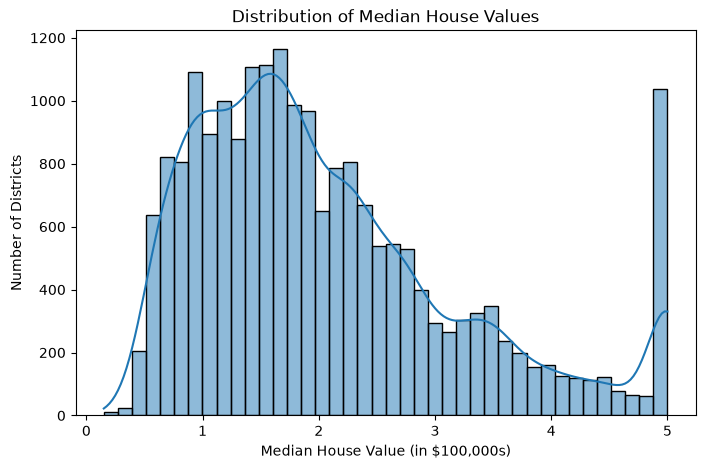

In [10]:

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="MedHouseVal", bins=40, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (in $100,000s)")
plt.ylabel("Number of Districts")
plt.show()


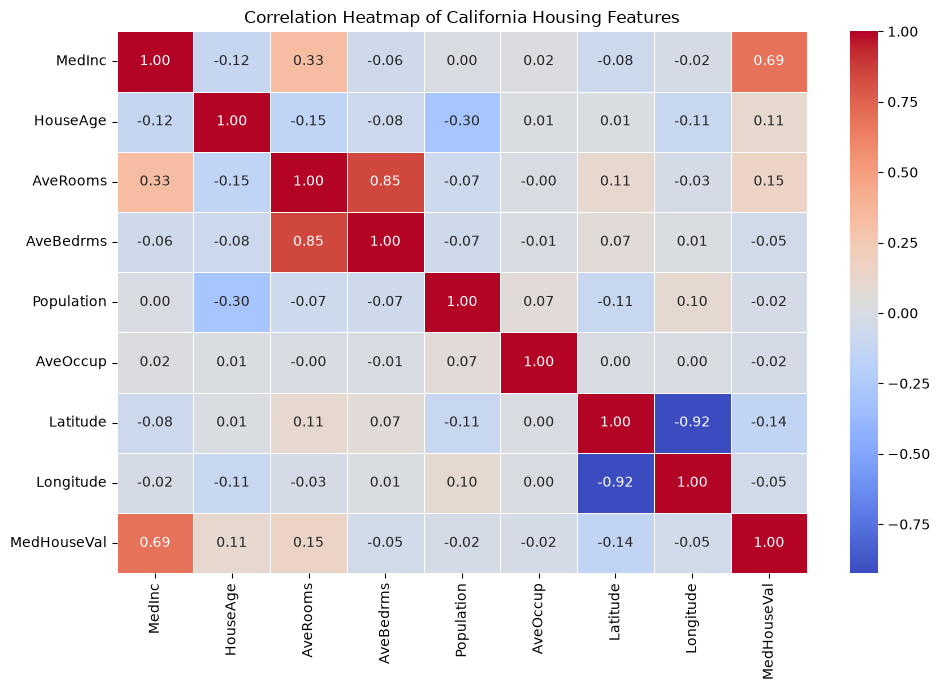

In [11]:

plt.figure(figsize=(10, 7))
correlation = df.corr(numeric_only=True)
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of California Housing Features")
plt.tight_layout()
plt.show()


### Correlation Heatmap - Observations

- `MedInc` has the strongest positive correlation with `MedHouseVal` (approximately 0.69), indicating that districts with higher median incomes generally have higher house values.
- `AveRooms` has a weak positive correlation with house values.
- `AveBedrms` has a very weak negative correlation with house values.
- `Latitude` and `Longitude` have weak overall linear correlations with house values, but location can still influence housing prices.
- `Population` and `AveOccup` have very weak linear correlations with house values.
- Overall, `MedInc` appears to be the most strongly linearly associated feature with the target variable, `MedHouseVal`. However, correlation alone does not determine a feature's usefulness for prediction.

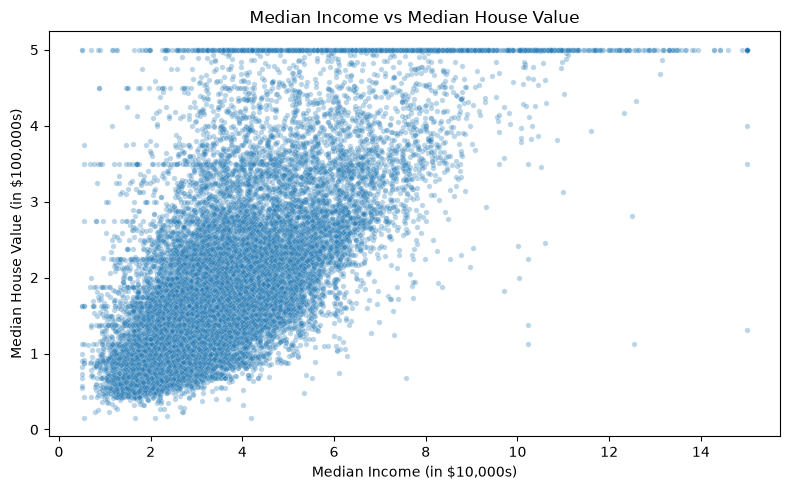

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.3,
    s=15
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income (in $10,000s)")
plt.ylabel("Median House Value (in $100,000s)")

plt.tight_layout()
plt.show()

### Scatter Plot - Observations

- The scatter plot shows a positive relationship between median income and median house value.
- Districts with higher median incomes generally have higher house values.
- The points are widely scattered, indicating that other features also influence house prices.
- A horizontal ceiling is visible near a median house value of 5.0, corresponding to $500,000 in the dataset's units.

**Conclusion:** Median income appears to be an important predictor of house values, but it cannot explain all price variations on its own.

In [13]:
# Separate features and target

X = df.drop("MedHouseVal",axis=1)
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


In [15]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=12345)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


In [16]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [18]:
# Predict house values using the test data
y_pred = model.predict(X_test)

# Display the first 10 actual and predicted values
results = pd.DataFrame({
    "Actual Price": y_test.iloc[:10].values,
    "Predicted Price": y_pred[:10]
})

print(results)

   Actual Price  Predicted Price
0       3.22300         3.172324
1       2.43300         2.332816
2       1.19000         1.540321
3       3.14900         2.715579
4       0.67500         0.559524
5       1.22400         1.858609
6       5.00001         4.298557
7       3.02600         3.125412
8       0.58000         0.752670
9       5.00000         2.574720


In [20]:
# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation Results
MAE:  0.5340
MSE:  0.5459
RMSE: 0.7389
R² Score: 0.5897


In [22]:
import joblib
import os

# Create a folder to store the trained model
os.makedirs("artifacts", exist_ok=True)

# Save the trained model
joblib.dump(model, "artifacts/linear_regression_model.pkl")


['artifacts/linear_regression_model.pkl']